In [ ]:
!pip install -q ultralytics roboflow

from ultralytics import YOLO
import roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.8/195.8 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 142.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
roboflow.login()

visit https://app.roboflow.com/auth-cli to get your authentication token.
Paste the authentication token here: ··········


In [ ]:
# download forked dataset from Roboflow
rf = roboflow.Roboflow()
project = rf.workspace("workspace-2s9cs").project("hafnarvaktin")
dataset = project.version(3).download("yolov11")
dataset_path = dataset.location

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to hafnarvaktin-3 in yolov11:: 100%|██████████| 205/205 [00:00<00:00, 2454.79it/s]


In [ ]:
# sanity-check splits + classes
import os
import yaml

# Count images in each split
for split in ('train', 'valid', 'test'):
      img_dir = os.path.join(dataset_path, split, 'images')
      if os.path.isdir(img_dir):
          count = len(os.listdir(img_dir))
          print(f'{split}: {count} images')
      else:
          print(f'{split}: (missing images!')

# Show class names from data.yaml
with open(os.path.join(dataset_path, 'data.yaml'), 'r') as f:
      config = yaml.safe_load(f)

print(f'\nClasses ({config["nc"]} total):')
for i, name in enumerate(config['names']):
      print(f'  {i}: {name}')

train: 80 images
valid: 10 images
test: 10 images

Classes (1 total):
  0: boat


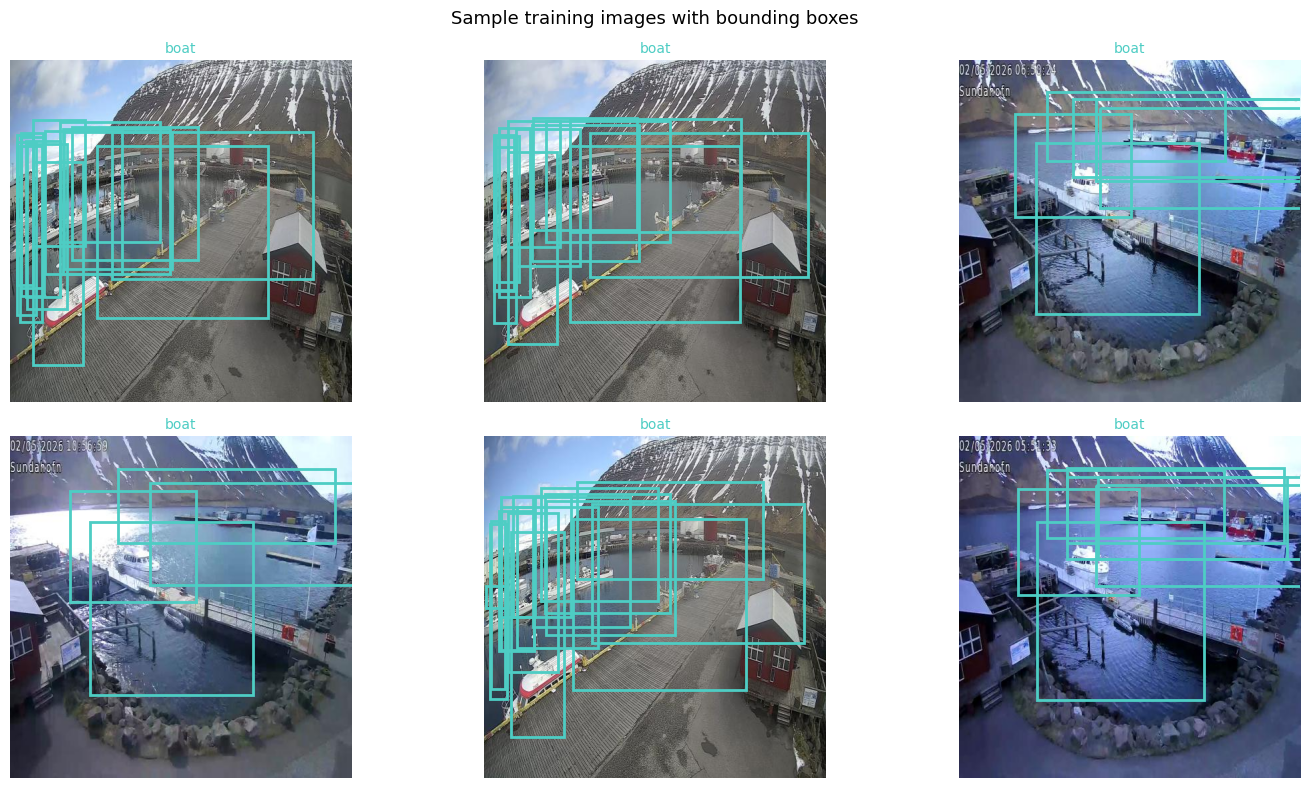

In [ ]:
# Sample frames + ground-truth boxes
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

train_img_dir = os.path.join(dataset_path, 'train', 'images')
train_lbl_dir = os.path.join(dataset_path, 'train', 'labels')

class_names = config['names']
colors      = ['#4ECDC4']

# Pick 6 random images from training folder
sample_files = random.sample(os.listdir(train_img_dir), 6)

# 2 rows, 3 columns — one image per subplot
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # flatten so we can loop over axes as a simple list

for ax, img_file in zip(axes, sample_files):
      img_path = os.path.join(train_img_dir, img_file)

      # Label file has the same name as the image but with .txt extension
      lbl_path = os.path.join(train_lbl_dir, os.path.splitext(img_file)[0] + '.txt')

      img = Image.open(img_path)
      w, h = img.size  # need pixel dimensions to convert YOLO coords back to pixels

      ax.imshow(img)
      ax.axis('off')

      if os.path.exists(lbl_path):
          with open(lbl_path) as f:
              for line in f:
                  parts = line.strip().split()
                  if not parts:
                      continue

                  cls = int(parts[0])

                  # skip class indices outside our dataset's class list
                  if cls < 0 or cls >= len(class_names):
                      continue

                  # YOLO format: center_x, center_y, width, height — all normalized 0-1
                  cx, cy, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])

                  # Convert normalized coords to actual pixel positions for drawing
                  x1 = (cx - bw / 2) * w  # left edge
                  y1 = (cy - bh / 2) * h  # top edge

                  # Draw the bounding box as a colored rectangle (no fill)
                  rect = patches.Rectangle(
                      (x1, y1), bw * w, bh * h,
                      linewidth=2, edgecolor=colors[cls % len(colors)], facecolor='none'
                  )
                  ax.add_patch(rect)
                  ax.set_title(class_names[cls], color=colors[cls % len(colors)], fontsize=10)

plt.suptitle('Sample training images with bounding boxes', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
# Train model
from ultralytics import YOLO
import os

model = YOLO('yolo11m.pt')

results = model.train(
    data=os.path.join(dataset_path, 'data.yaml'),
    epochs=150,
    imgsz=640, #resize all images to 640x640 (YOLO standard)
    batch=16, #process 16 images at a time before updating weights
    patience=20,#stop early if val score doesn't improve for 10 epochs
    device=0 #use the GPU
)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hafnarvaktin-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20

In [ ]:
# evaluate on test set (conf=0.10)
val_results = model.val(
    data=os.path.join(dataset_path, 'data.yaml'),
    split='test',
    conf=0.10
)

print('\n' + '=' * 40)
print('EVALUATION RESULTS (test set)')
print('=' * 40)
print(f"Precision : {val_results.results_dict['metrics/precision(B)']:.3f}")
print(f"Recall    : {val_results.results_dict['metrics/recall(B)']:.3f}")
print(f"mAP50     : {val_results.results_dict['metrics/mAP50(B)']:.3f}")
print('=' * 40)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 126 layers, 20,030,803 parameters, 0 gradients, 67.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 118.4±137.2 MB/s, size: 51.2 KB)
val: Scanning /content/hafnarvaktin-3/test/labels... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 361.8it/s 0.0s
val: /content/hafnarvaktin-3/test/images/cam06_20260501T200706Z_boat_61_jpg.rf.9a78204147697c71511384649bea4739.jpg: 1 duplicate labels removed
val: New cache created: /content/hafnarvaktin-3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.9it/s 0.5s
                   all         10        120      0.916      0.907      0.893      0.697
Speed: 1.3ms preprocess, 34.8ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/runs/detect/val

EVALUATION RESULTS (test set)
Precision : 0.916
Recall    : 0.907
mAP5

In [ ]:
# Save best.pt
import shutil, glob, os

run_dir = sorted(glob.glob('/content/runs/detect/train*'))[-1]
src = os.path.join(run_dir, 'weights', 'best.pt')

# save to Drive:
# from google.colab import drive; drive.mount('/content/drive')
# shutil.copy(src, '/content/drive/My Drive/KEA/ML/hafnarvaktin-yolo11m-best.pt')

# keep in /content/ to download via Colab
shutil.copy(src, '/content/hafnarvaktin-yolo11m-best.pt')
print(f'saved: /content/hafnarvaktin-yolo11m-best.pt')
print(f'size : {os.path.getsize(src)/1e6:.1f} MB')

saved: /content/hafnarvaktin-yolo11m-best.pt
size : 40.5 MB


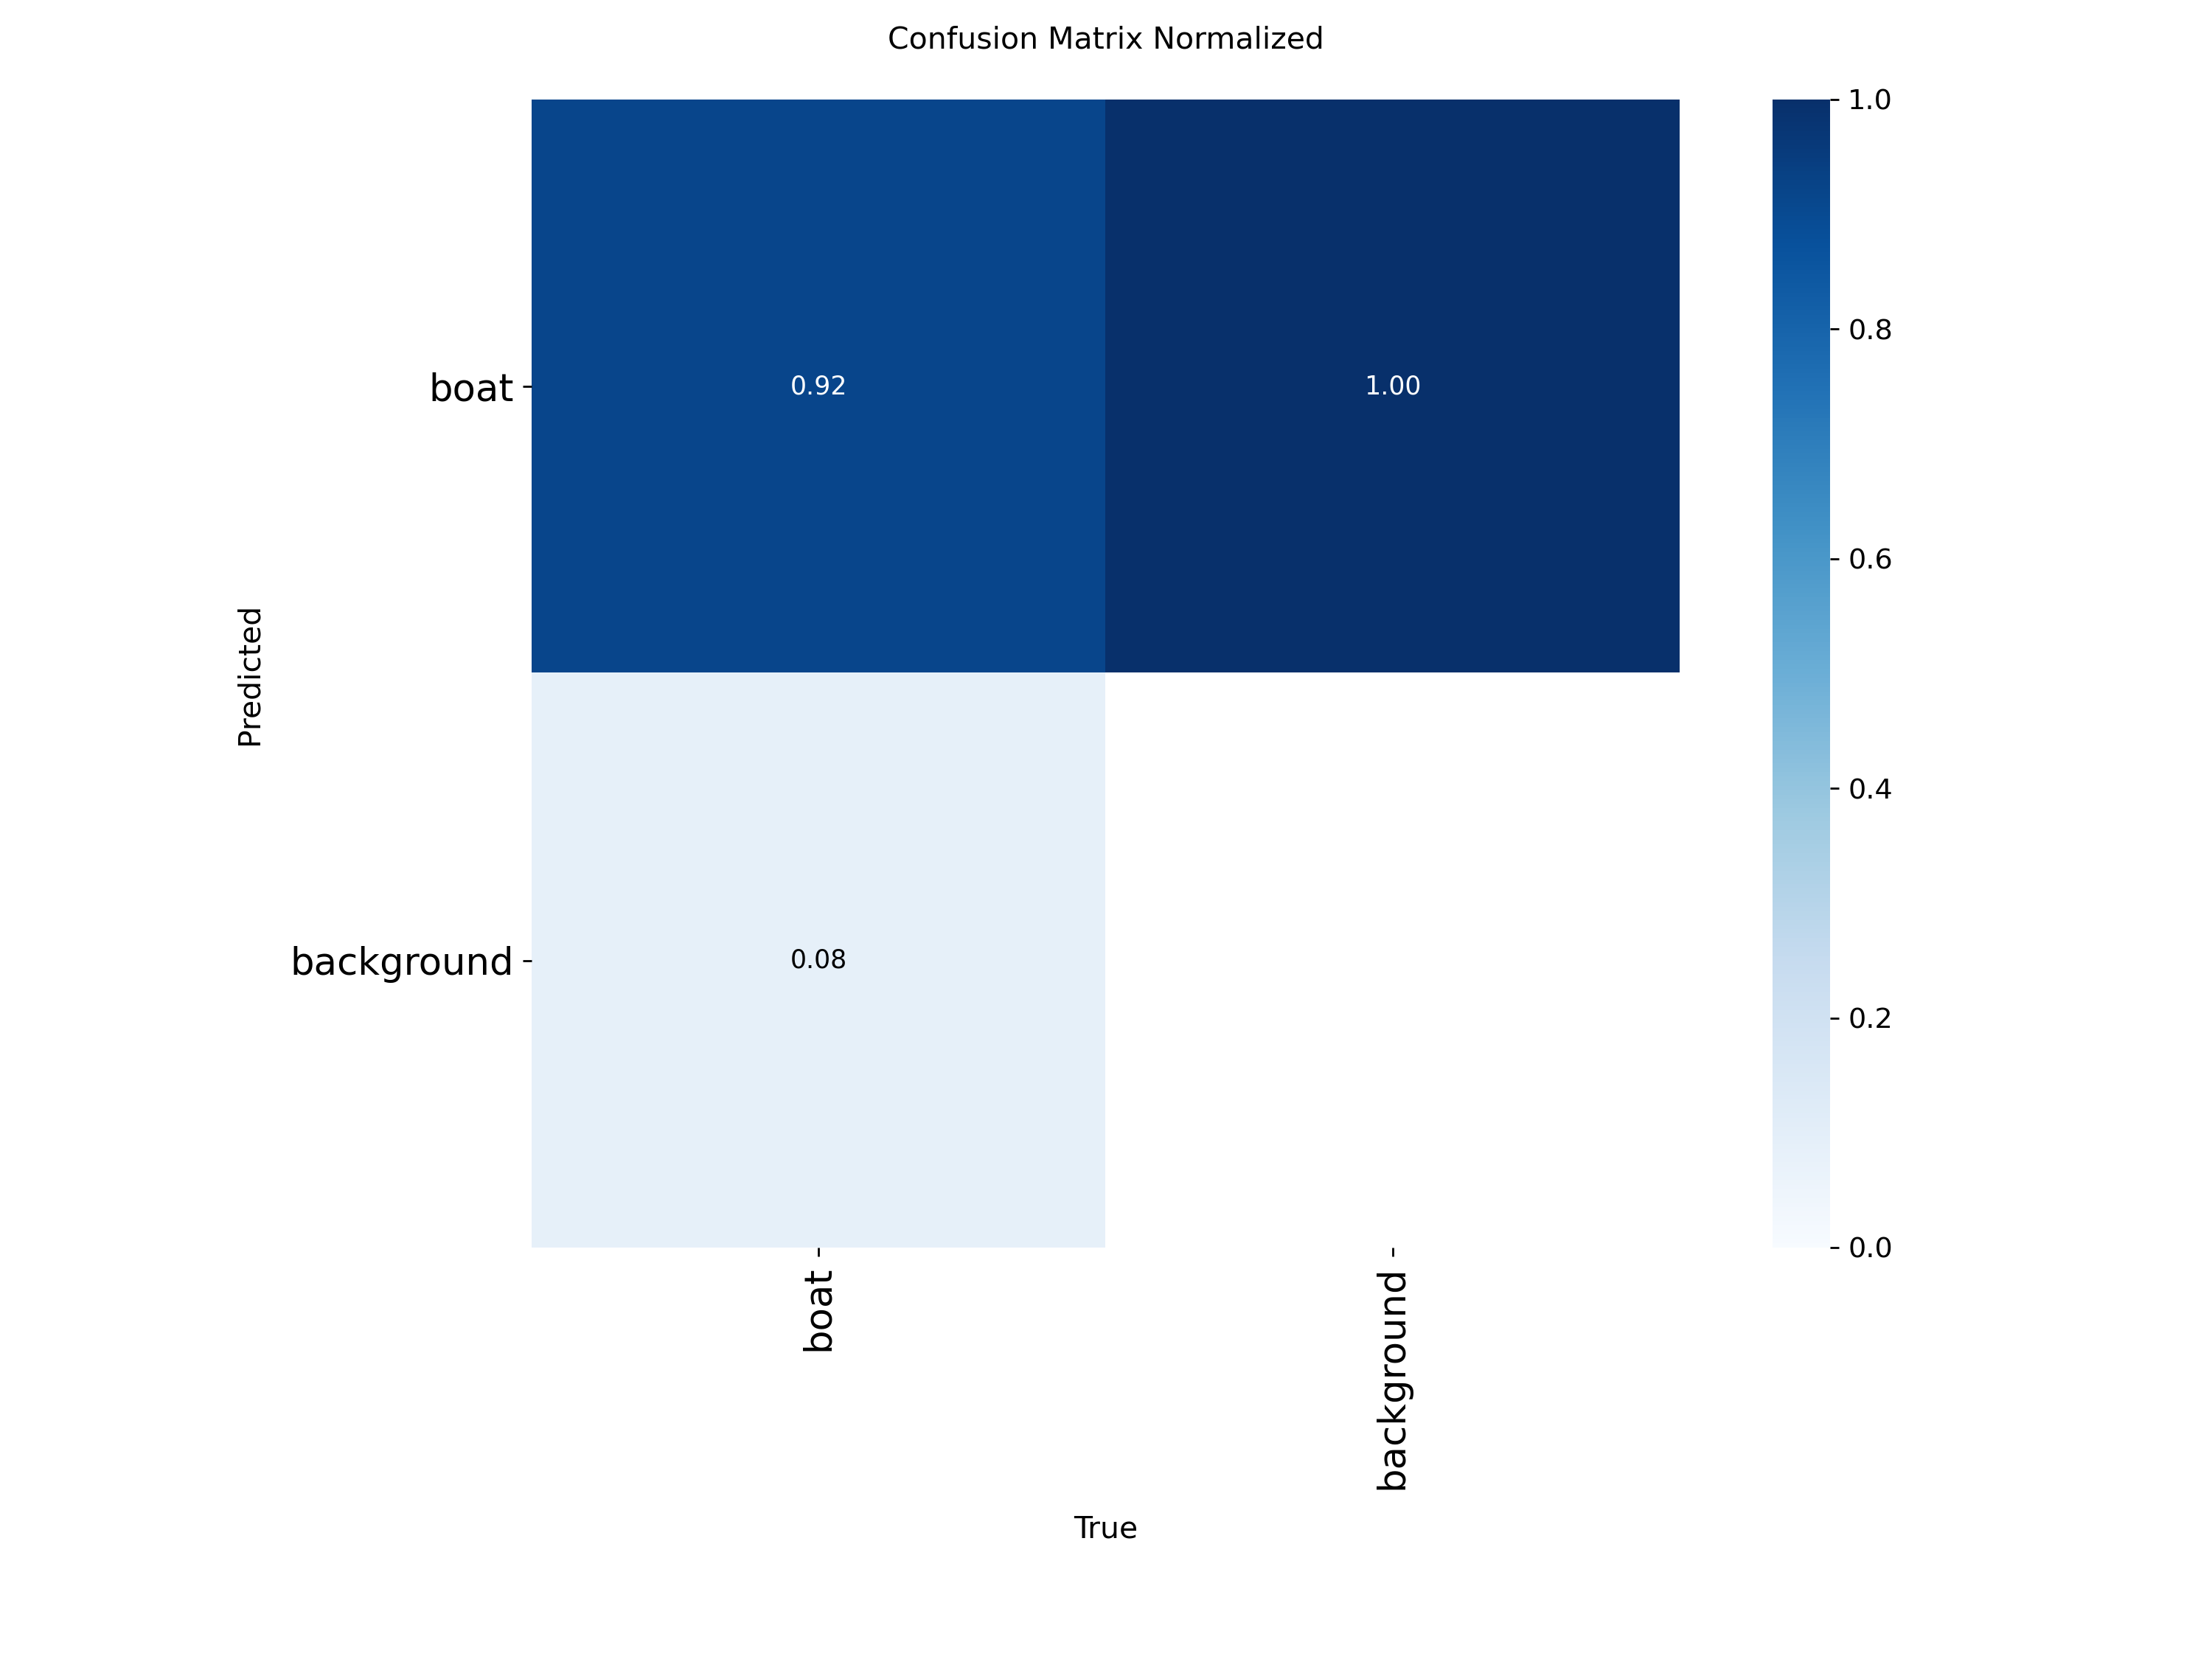

In [ ]:
# Confusion matrix
from IPython.display import Image as IPImage
import glob

cm_path = glob.glob('/content/runs/detect/val*/confusion_matrix_normalized.png')

if cm_path:
    display(IPImage(cm_path[0], width=600))
else:
    print('Not found — check /content/runs/detect/')

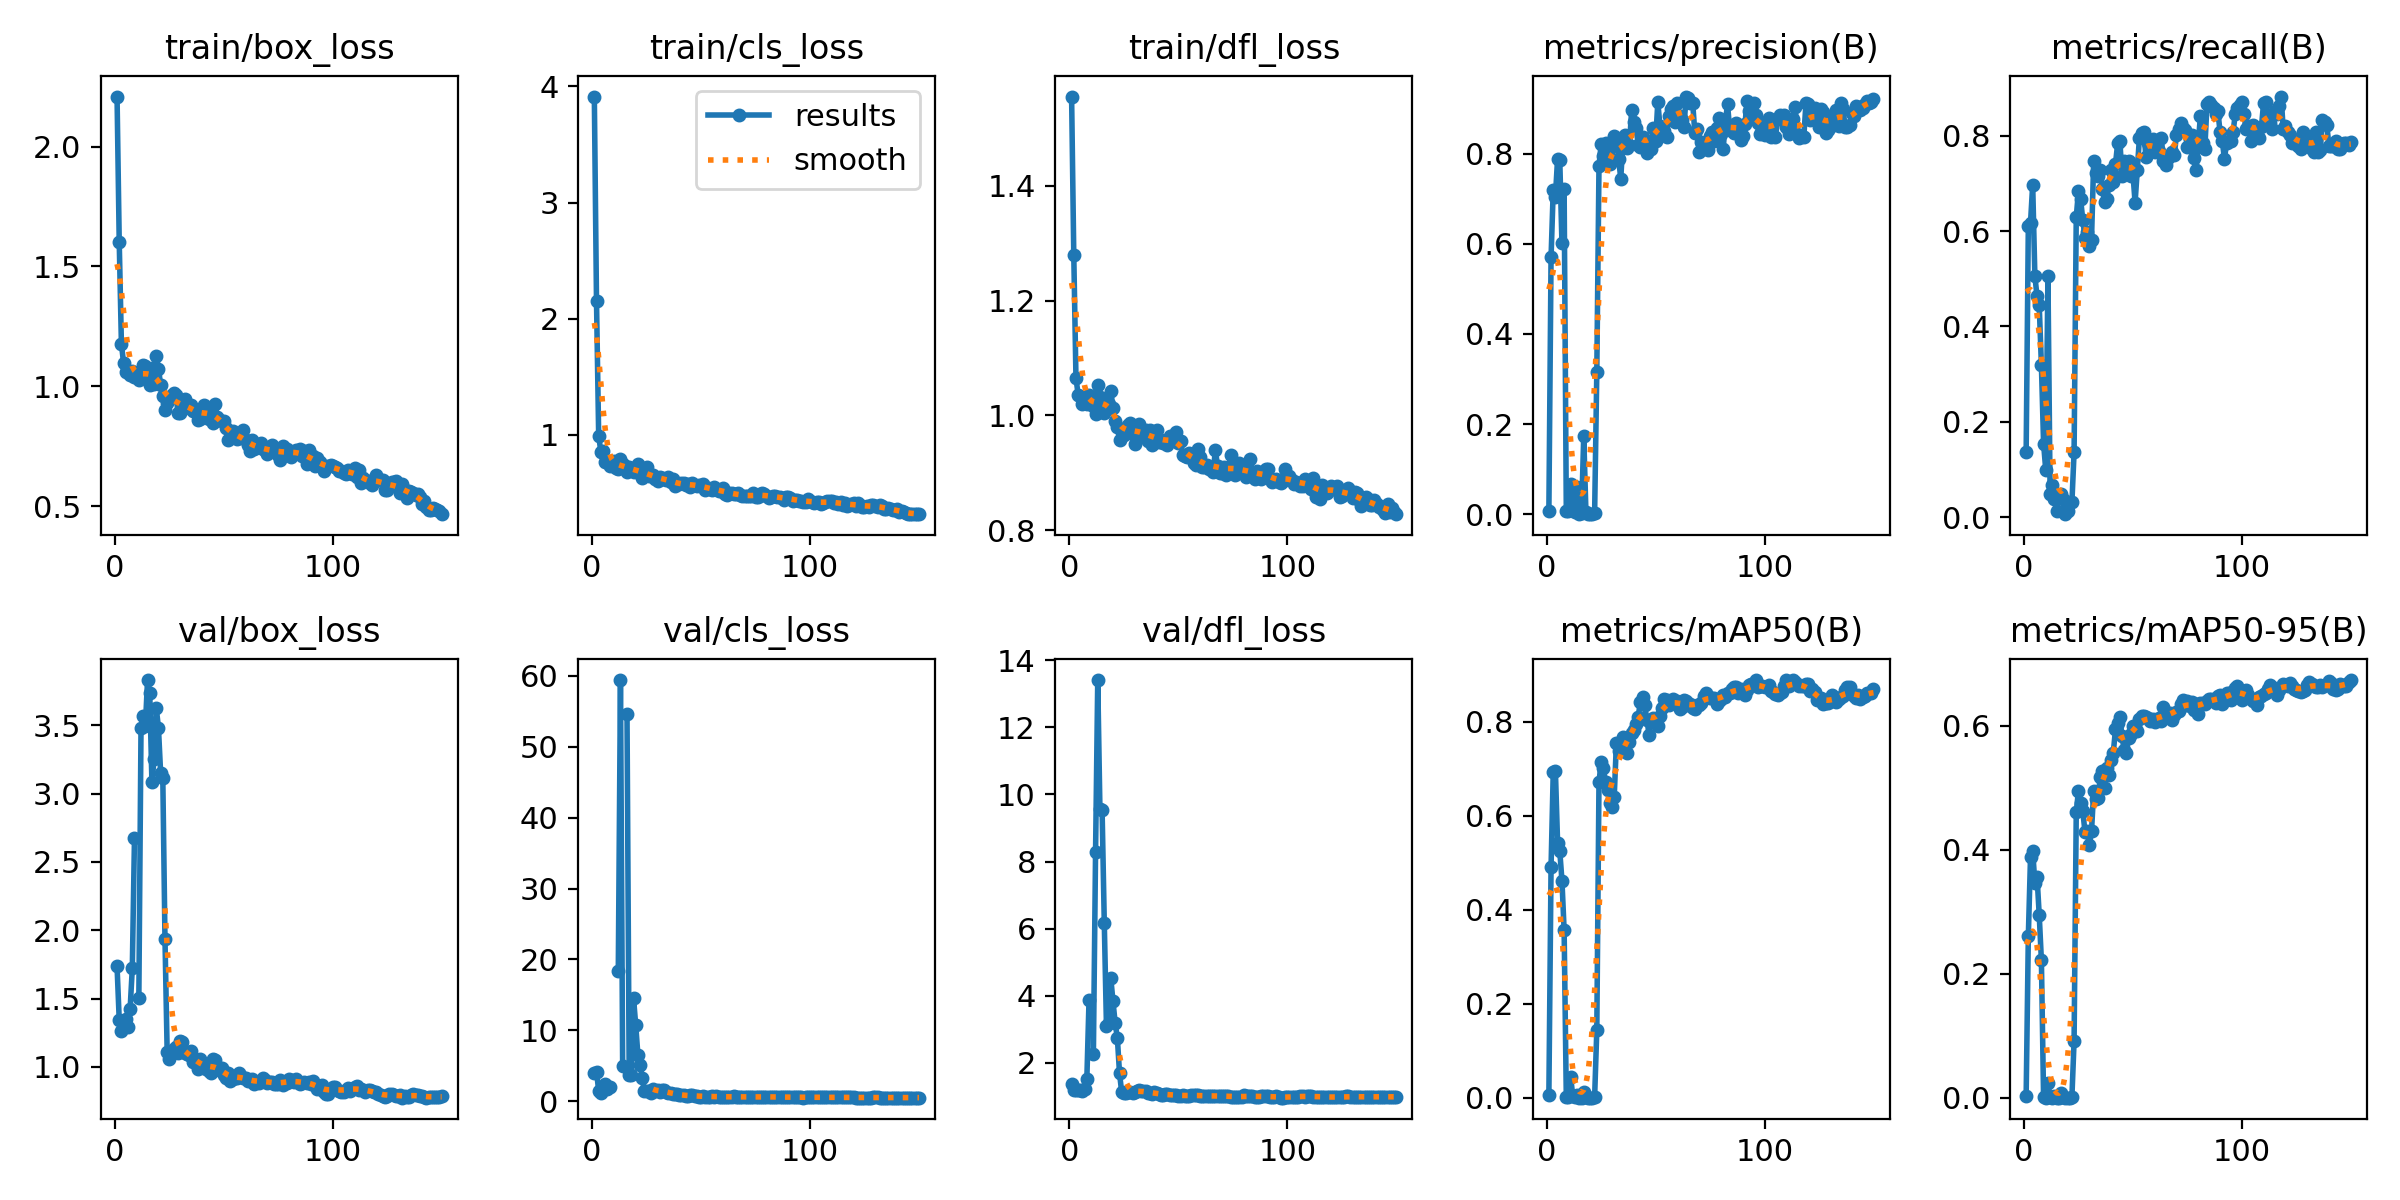

In [ ]:
# Display training curves
from IPython.display import Image as IPImage
import glob, os

run_dir = sorted(glob.glob('/content/runs/detect/train*'))[-1]
display(IPImage(os.path.join(run_dir, 'results.png'), width=900))

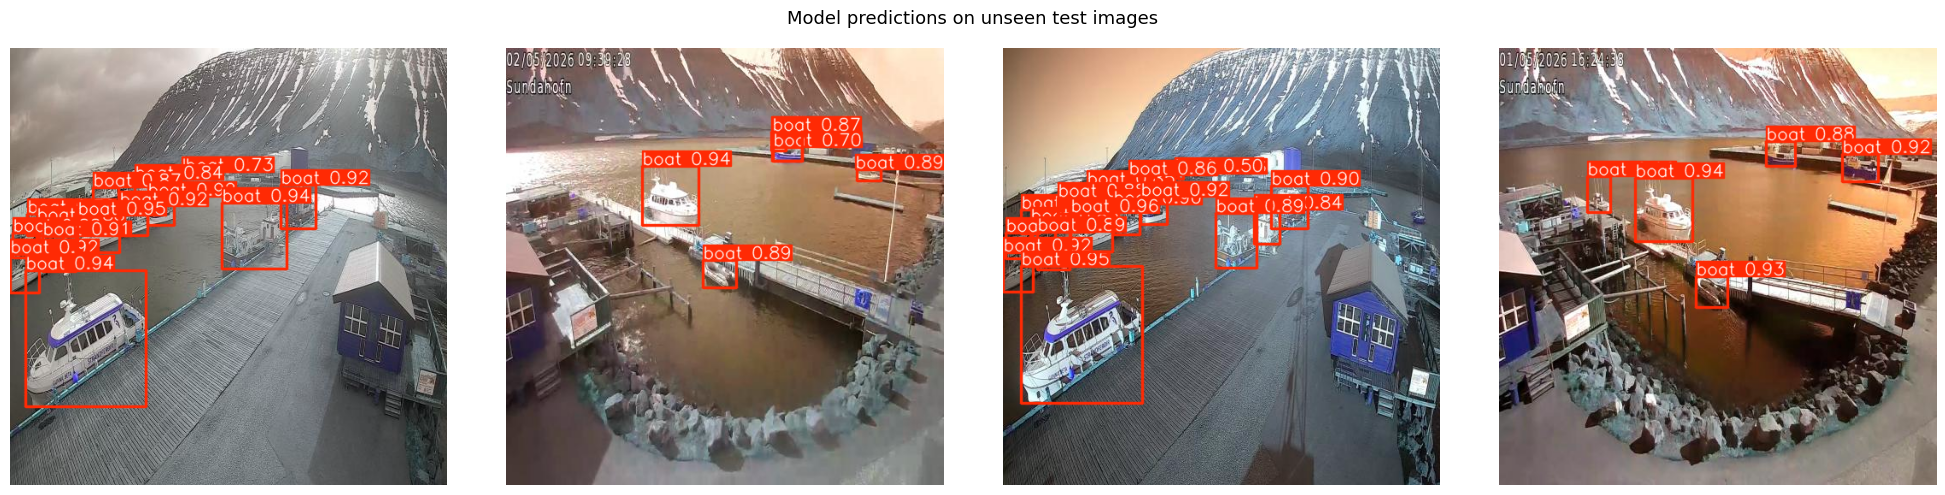

In [ ]:
# Sample predictions
import random
import matplotlib.pyplot as plt

test_img_dir = os.path.join(dataset_path, 'test', 'images')
sample_images = random.sample(os.listdir(test_img_dir), 4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, img_file in zip(axes, sample_images):
    img_path = os.path.join(test_img_dir, img_file)

    # Run inference — returns a list of result objects
    predictions = model(img_path, verbose=False)

    # draw bounding boxes on image and return numpy array
    annotated = predictions[0].plot()

    ax.imshow(annotated)
    ax.axis('off')

plt.suptitle('Model predictions on unseen test images', fontsize=13)
plt.tight_layout()
plt.show()